# Basic Usage

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

import utils
sys.path.append(str((Path.cwd().parent / "indirect_space_charge_python").resolve()))
from install import install_spacecharge_frozen

## Parameters

In [2]:
nemitt_x = 1e-6
nemitt_y = 1e-6
aperture_size = 6e-3 
intensity=1e12 # Number of particles in coasting beam
nodes = 4 # Number of spacecharge nodes

## Create Line

In [3]:
line = xt.Line(
    elements=[
        xt.LimitRect(min_x=-aperture_size/2, max_x=aperture_size/2, min_y=-aperture_size/2, max_y=aperture_size/2),
        xt.Quadrupole(length=0.5, k1=1.25),
        xt.LimitRect(min_x=-aperture_size/2, max_x=aperture_size/2, min_y=-aperture_size/2, max_y=aperture_size/2),
        xt.Drift(length=1.5),
        xt.LimitRect(min_x=-aperture_size/2, max_x=aperture_size/2, min_y=-aperture_size/2, max_y=aperture_size/2),
        xt.Quadrupole(length=0.5, k1=-1.20),
        xt.LimitRect(min_x=-aperture_size/2, max_x=aperture_size/2, min_y=-aperture_size/2, max_y=aperture_size/2),
        xt.Drift(length=1.5),
    ],
    element_names=['aper_1', 'fquad', 
                   'aper_2', 'drift_1',
                   'aper_3', 'dquad',
                   'aper_4', 'drift_2']
)
line.set_particle_ref('proton', p0c=7e9)
tw = line.twiss4d()

## Add Space charge frozen

`install_spacecharge_frozen()` is similar to `xfields`'s function of the same name.

```python
def install_spacecharge_frozen(line, # line to add space charge elements to
                               number_of_particles,
                               num_spacecharge_interactions,
                               nemitt_x, nemitt_y,
                               indirect_sc = True, # flag to toggle indirect space charge on or off
                               particle_ref=None, # In case not given in line
                               node_s_list=None, # In case you wanted to specify where space charge nodes are
                               prefix='spacecharge_', # What the beam elements will be named
                               _enlargement=1 # A developer argument that scales the beampipe lengths i.e. makes the pipe bigger or smaller
                              ):
    # ...
    return line # Returns the line with the space charge elements added
```

In [4]:
# Xsuite - this is a wrapper for `xfield`'s `install_spacecharge_frozen` which allows for coasting beams
line_xfield = utils.install_spacecharge_frozen(line.copy(), number_of_particles=intensity,
                                  num_spacecharge_interactions=nodes,
                                  nemitt_x=nemitt_x, nemitt_y=nemitt_y)
line_xfield.build_tracker()

# Custom space charge model without indirect space charge - should be the same as Xsuite
line_custom_direct = install_spacecharge_frozen(line.copy(), number_of_particles=intensity,
                                  num_spacecharge_interactions=nodes,
                                  nemitt_x=nemitt_x, nemitt_y=nemitt_y,
                                  indirect_sc=False)
line_custom_direct.build_tracker()

# Custom space charge model with indirect space charge
line_custom_indirect = install_spacecharge_frozen(line.copy(), number_of_particles=intensity,
                                  num_spacecharge_interactions=nodes,
                                  nemitt_x=nemitt_x, nemitt_y=nemitt_y,
                                  indirect_sc=True)
line_custom_indirect.build_tracker()

Slicing line: 100%|██████████| 8/8 [00:00<00:00, 38130.04it/s]


The line already has an associated tracker


Slicing line: 100%|██████████| 8/8 [00:00<00:00, 36118.87it/s]

The line already has an associated tracker


## Tune footprints
Custom get_footprint function similar to `xtrack`'s inbuilt but allows for coasting collective tracking

In [5]:
fp_xfield = utils.get_footprint_4d(line_xfield, nemitt_x, nemitt_y, keep_tracking_data=True)
fp_custom_direct = utils.get_footprint_4d(line_custom_direct, nemitt_x, nemitt_y, keep_tracking_data=True)
fp_custom_indirect = utils.get_footprint_4d(line_custom_indirect, nemitt_x, nemitt_y, keep_tracking_data=True)


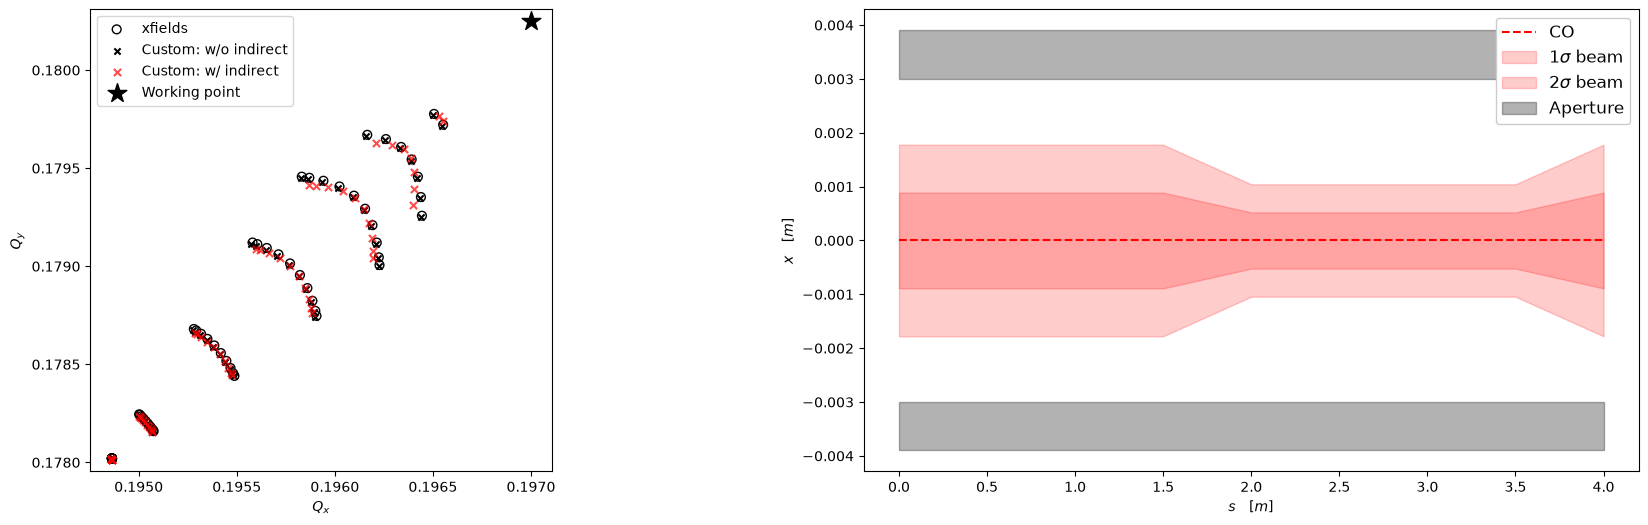

In [6]:
size=40
fig, axs = plt.subplots(1,2, figsize=(22,6))
axs[0].set_aspect('equal')
axs[0].set_box_aspect(1)
axs[0].scatter(fp_xfield.qx,fp_xfield.qy, edgecolors='k', facecolors='none', s=size, marker='o', linewidth=1, label='xfields')
axs[0].scatter(fp_custom_direct.qx,fp_custom_direct.qy, c='k', s=size/2, marker='x', linewidth=1.5, label='Custom: w/o indirect')
axs[0].scatter(fp_custom_indirect.qx,fp_custom_indirect.qy, c='r', s=size/1.5, marker='x', linewidth=1.5, label='Custom: w/ indirect', alpha=0.7)
axs[0].scatter(tw.qx,tw.qy, c='k', s=size*5, marker='*', label='Working point')
axs[0].set_xlabel(r'$Q_x$')
axs[0].set_ylabel(r'$Q_y$')
axs[0].legend()

sigma_x = np.sqrt(tw.betx*nemitt_x/(line.particle_ref.beta0*line.particle_ref.gamma0))
s = np.linspace(0,line.get_length(),len(tw.x))
apers = aperture_size/2*np.ones_like(tw.x)
axs[1].plot(s, tw.x, c='r', ls='--', label='CO')
axs[1].fill_between(s, tw.x-sigma_x, tw.x+sigma_x, color='r', alpha=0.2, label=r'$1\sigma$ beam')
axs[1].fill_between(s, tw.x-2*sigma_x, tw.x+2*sigma_x, color='r', alpha=0.2, label=r'$2\sigma$ beam')
axs[1].fill_between(s, -1.3*apers,-apers, color='k', alpha=0.3, label='Aperture')
axs[1].fill_between(s, apers,1.3*apers, color='k', alpha=0.3)
axs[1].set_xlabel(r'$s \quad [m]$')
axs[1].set_ylabel(r'$x \quad [m]$')
axs[1].legend(loc='upper right', framealpha=1, fontsize='large')

Note that indirect space charge has the effect of narrowing the tune footprint - this is generally true.